# Temporal Graph Networks: mlx-graphs vs PyG

Many graphs are not static: they are streams of timestamped events, such as a user editing a Wikipedia page, a student taking a course, or a payment between two accounts. A **Temporal Graph Network** (TGN, [Rossi et al., 2020](https://arxiv.org/abs/2006.10637)) learns from such streams by keeping a **memory** vector for every node. Each new event sends a message to its two nodes, and a GRU updates their memories. To predict a future event, TGN embeds the involved nodes with a graph attention layer over their most recent interactions, and scores the pair.

In this tutorial, we train the same TGN with mlx-graphs and with PyTorch Geometric (PyG) on the JODIE Wikipedia dataset. We then compare the **average precision** (AP) of the predicted links and the **time per epoch**. The model is PyG's [examples/tgn.py](https://github.com/pyg-team/pytorch_geometric/blob/master/examples/tgn.py), with the same hyperparameters in both frameworks.

The PyG part needs a few extra dependencies:

`pip install torch torch_geometric scikit-learn pandas matplotlib`

![TGN pipeline: JODIE Wikipedia events (9,227 nodes, 157k events) are split by time and batched by TemporalDataLoader; TGNMemory (IdentityMessage, LastAggregator, GRUCell) reads the node memory, GraphAttentionEmbedding applies a TransformerConv over the 10 latest neighbors from LastNeighborLoader, and LinkPredictor scores positive and negative pairs; after the BCE loss the batch events are written to the memory and Adam updates the weights; AP and ROC AUC on the validation and test events are compared with PyG](../../_static/tutorials/temporal_graph_networks.svg)

In [1]:
import time

import mlx.core as mx
import mlx.nn as nn
import mlx.optimizers as optim
import numpy as np

from mlx_graphs.datasets import JODIEDataset
from mlx_graphs.loaders import TemporalDataLoader
from mlx_graphs.metrics import average_precision_score, roc_auc_score
from mlx_graphs.nn import TGNMemory, TransformerConv
from mlx_graphs.nn.models.tgn import (
    IdentityMessage,
    LastAggregator,
    LastNeighborLoader,
    TimeEncoder,
)

# Same hyperparameters as PyG's examples/tgn.py
EPOCHS = 10
BATCH_SIZE = 200
LR = 1e-4
DIM = 100  # memory, time encoding and embedding sizes
NUM_NEIGHBORS = 10
SEED = 0

## The dataset

JODIE Wikipedia has 157,474 edits by 8,227 users of 1,000 pages over one month. Each event is a `(src, dst, t, msg)` tuple: a user, a page, a timestamp in seconds, and a 172-dimensional feature vector of the edit text. mlx-graphs stores the stream in a `TemporalData` object.

In [2]:
dataset = JODIEDataset("wikipedia")
data = dataset[0]
print(data)
print(
    f"{data.num_nodes} nodes, {data.num_events} events, "
    f"message size {data.msg.shape[1]}"
)

Loading jodie_wikipedia data ... Done
TemporalData(src=[157474], dst=[157474], t=[157474], msg=[157474, 172], y=[157474])
9227 nodes, 157474 events, message size 172


The events are split **by time**: the first 70% are used for training, the next 15% for validation and the last 15% for testing. A `TemporalDataLoader` iterates over the events in mini-batches of 200, in chronological order, and draws a random negative destination for every event. The `LastNeighborLoader` keeps the 10 most recent neighbors of every node, which form the subgraph the attention layer looks at.

In [3]:
train_data, val_data, test_data = data.train_val_test_split(
    val_ratio=0.15, test_ratio=0.15
)

train_loader = TemporalDataLoader(
    train_data, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0
)
val_loader = TemporalDataLoader(val_data, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0)
test_loader = TemporalDataLoader(
    test_data, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0
)
neighbor_loader = LastNeighborLoader(data.num_nodes, size=NUM_NEIGHBORS)

print(
    f"train: {train_data.num_events}, val: {val_data.num_events}, "
    f"test: {test_data.num_events} events"
)

train: 110232, val: 23621, test: 23621 events


## The model in mlx-graphs

The model has three parts:

- `TGNMemory` holds one memory vector per node, and updates it from the messages of the past events with a GRU. `IdentityMessage` builds a message from the two memories, the time since the last update and the event features, and `LastAggregator` keeps the most recent message of each node.
- `GraphAttentionEmbedding` embeds the nodes with a `TransformerConv` over the recent interactions. Each edge carries the encoding of its relative time and its event features.
- `LinkPredictor` scores a `(source, destination)` pair from the two embeddings.

The memory is a state, not a parameter: `nn.value_and_grad` and the optimizer only see the weights of the modules. The time encoder is shared between the memory and the attention layer. It is passed to the attention layer at call time, so that it appears only once in the parameters of the model.

In [4]:
class GraphAttentionEmbedding(nn.Module):
    def __init__(self, in_dim, out_dim, msg_dim, time_dim):
        super().__init__()
        self.conv = TransformerConv(
            in_dim,
            out_dim // 2,
            heads=2,
            dropout=0.1,
            edge_features_dim=msg_dim + time_dim,
        )

    def __call__(self, x, last_update, edge_index, t, msg, time_enc: TimeEncoder):
        rel_t = (last_update[edge_index[0]] - t).astype(x.dtype)
        edge_features = mx.concatenate([time_enc(rel_t), msg], axis=-1)
        return self.conv(edge_index, x, edge_features)


class LinkPredictor(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.lin_src = nn.Linear(dim, dim)
        self.lin_dst = nn.Linear(dim, dim)
        self.lin_final = nn.Linear(dim, 1)

    def __call__(self, z_src, z_dst):
        return self.lin_final(nn.relu(self.lin_src(z_src) + self.lin_dst(z_dst)))


class TGN(nn.Module):
    def __init__(self, num_nodes, msg_dim, dim):
        super().__init__()
        self.memory = TGNMemory(
            num_nodes,
            msg_dim,
            dim,
            dim,
            message_module=IdentityMessage(msg_dim, dim, dim),
            aggregator_module=LastAggregator(),
        )
        self.gnn = GraphAttentionEmbedding(dim, dim, msg_dim, dim)
        self.link_pred = LinkPredictor(dim)

    def __call__(self, n_id, edge_index, e_id, src, pos_dst, neg_dst):
        z, last_update = self.memory(n_id)
        z = self.gnn(
            z,
            last_update,
            edge_index,
            data.t[e_id],
            data.msg[e_id],
            self.memory.time_enc,
        )
        return self.link_pred(z[src], z[pos_dst]), self.link_pred(z[src], z[neg_dst])


def loss_fn(model, *args):
    pos_out, neg_out = model(*args)
    return nn.losses.binary_cross_entropy(
        pos_out, mx.ones_like(pos_out)
    ) + nn.losses.binary_cross_entropy(neg_out, mx.zeros_like(neg_out))

For every mini-batch, the neighbor loader returns the nodes `n_id` involved (the batch's nodes and their recent neighbors), the edges between them and their event ids. `assoc` maps the global ids of the batch's nodes to their position in `n_id`.

After the loss is computed, the batch's events are written to the memory and to the neighbor loader. The model therefore never sees an event before predicting it. `memory.detach()` then cuts the gradient through the memory, as PyG does after the optimizer step.

In [5]:
assoc = np.zeros(data.num_nodes, dtype=np.int64)


def prepare(batch):
    n_id, edge_index, e_id = neighbor_loader(batch.n_id)
    assoc[np.array(n_id)] = np.arange(n_id.size)

    def local(nodes):
        return mx.array(assoc[np.array(nodes)].astype(np.int32))

    return (
        n_id,
        edge_index,
        e_id,
        local(batch.src),
        local(batch.dst),
        local(batch.neg_dst),
    )


def train(model, optimizer):
    model.train()
    model.memory.reset_state()  # start with a fresh memory
    neighbor_loader.reset_state()  # and an empty graph
    loss_and_grad = nn.value_and_grad(model, loss_fn)

    total_loss = 0.0
    for batch in train_loader:
        loss, grads = loss_and_grad(model, *prepare(batch))
        model.memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
        neighbor_loader.insert(batch.src, batch.dst)
        optimizer.update(model, grads)
        model.memory.detach()
        mx.eval(model.parameters(), optimizer.state, loss)
        total_loss += loss.item() * batch.num_events
    return total_loss / train_data.num_events


def test(model, loader):
    model.eval()  # also flushes the pending messages into the memory
    mx.random.seed(12345)  # same negative destinations at every epoch

    aps, aucs = [], []
    for batch in loader:
        pos_out, neg_out = model(*prepare(batch))
        y_pred = np.array(mx.sigmoid(mx.concatenate([pos_out, neg_out]))).reshape(-1)
        y_true = np.concatenate([np.ones(pos_out.shape[0]), np.zeros(neg_out.shape[0])])
        aps.append(average_precision_score(y_true, y_pred))
        aucs.append(roc_auc_score(y_true, y_pred))

        model.memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
        neighbor_loader.insert(batch.src, batch.dst)
    return float(np.mean(aps)), float(np.mean(aucs))

## Training with mlx-graphs

Every epoch replays the training events from the start, then evaluates on the validation and test events, which follow them in time. We time the training and the evaluation separately.

In [6]:
def run_epochs(train_epoch, evaluate):
    history = []
    for epoch in range(1, EPOCHS + 1):
        start = time.perf_counter()
        loss = train_epoch()
        train_s = time.perf_counter() - start
        start = time.perf_counter()
        (val_ap, val_auc), (test_ap, test_auc) = evaluate()
        eval_s = time.perf_counter() - start
        history.append(
            dict(
                epoch=epoch,
                loss=loss,
                val_ap=val_ap,
                test_ap=test_ap,
                test_auc=test_auc,
                train_s=train_s,
                eval_s=eval_s,
            )
        )
        print(
            f"Epoch {epoch:02d}  loss {loss:.4f}  val AP {val_ap:.4f}  "
            f"test AP {test_ap:.4f}  "
            f"test AUC {test_auc:.4f}  train {train_s:.1f} s  eval {eval_s:.1f} s"
        )
    return history


mx.random.seed(SEED)
mlx_model = TGN(data.num_nodes, data.msg.shape[1], DIM)
# bias_correction=True gives the update rule of torch.optim.Adam
mlx_optimizer = optim.Adam(learning_rate=LR, bias_correction=True)

mlx_history = run_epochs(
    lambda: train(mlx_model, mlx_optimizer),
    lambda: (test(mlx_model, val_loader), test(mlx_model, test_loader)),
)

Epoch 01  loss 1.0761  val AP 0.9172  test AP 0.9086  test AUC 0.9099  train 4.6 s  eval 0.8 s
Epoch 02  loss 0.7353  val AP 0.9398  test AP 0.9346  test AUC 0.9295  train 4.9 s  eval 0.7 s
Epoch 03  loss 0.6845  val AP 0.9443  test AP 0.9399  test AUC 0.9338  train 4.8 s  eval 0.8 s
Epoch 04  loss 0.6533  val AP 0.9458  test AP 0.9388  test AUC 0.9329  train 4.6 s  eval 0.8 s
Epoch 05  loss 0.6288  val AP 0.9528  test AP 0.9502  test AUC 0.9457  train 4.9 s  eval 0.8 s
Epoch 06  loss 0.6143  val AP 0.9545  test AP 0.9497  test AUC 0.9453  train 5.5 s  eval 0.8 s
Epoch 07  loss 0.5989  val AP 0.9567  test AP 0.9516  test AUC 0.9478  train 4.1 s  eval 0.7 s
Epoch 08  loss 0.5757  val AP 0.9579  test AP 0.9554  test AUC 0.9519  train 4.4 s  eval 0.9 s
Epoch 09  loss 0.5663  val AP 0.9586  test AP 0.9552  test AUC 0.9511  train 5.4 s  eval 0.8 s
Epoch 10  loss 0.5557  val AP 0.9605  test AP 0.9568  test AUC 0.9531  train 4.6 s  eval 0.7 s


## The same model in PyG

The PyG version below is PyG's `examples/tgn.py`, with the same data, splits and hyperparameters. It runs on the CPU: PyG's TGN does many small indexing operations per batch, which are slower on the MPS backend.

One detail: without the optional `torch-scatter` package, PyG falls back to its own `scatter_argmax`, which gives nodes without messages the index `dim_size - 1` instead of an out-of-range one. Its `LastAggregator` then copies an unrelated message to every node without messages instead of zeros. mlx-graphs follows the `torch-scatter` behavior. For a like-for-like comparison, we patch the fallback when `torch-scatter` is not installed.

In [7]:
import torch
import torch_geometric.nn.models.tgn as pyg_tgn_module
from sklearn.metrics import average_precision_score as sk_ap
from sklearn.metrics import roc_auc_score as sk_auc
from torch_geometric.datasets import JODIEDataset as PyGJODIEDataset
from torch_geometric.loader import TemporalDataLoader as PyGTemporalDataLoader
from torch_geometric.nn import TGNMemory as PyGTGNMemory
from torch_geometric.nn import TransformerConv as PyGTransformerConv
from torch_geometric.nn.models.tgn import IdentityMessage as PyGIdentityMessage
from torch_geometric.nn.models.tgn import LastAggregator as PyGLastAggregator
from torch_geometric.nn.models.tgn import LastNeighborLoader as PyGLastNeighborLoader

try:
    import torch_scatter  # noqa: F401
except ImportError:

    def scatter_argmax(src, index, dim=0, dim_size=None):
        res = src.new_empty(dim_size)
        res.scatter_reduce_(0, index, src, reduce="amax", include_self=False)
        out = index.new_full((dim_size,), fill_value=src.size(0))
        nonzero = (src == res[index]).nonzero().view(-1)
        out[index[nonzero]] = nonzero
        return out

    pyg_tgn_module.scatter_argmax = scatter_argmax

torch.manual_seed(SEED)
pyg_data = PyGJODIEDataset(".pyg_data/JODIE", name="wikipedia")[0]
pyg_train, pyg_val, pyg_test = pyg_data.train_val_test_split(
    val_ratio=0.15, test_ratio=0.15
)
pyg_train_loader = PyGTemporalDataLoader(
    pyg_train, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0
)
pyg_val_loader = PyGTemporalDataLoader(
    pyg_val, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0
)
pyg_test_loader = PyGTemporalDataLoader(
    pyg_test, batch_size=BATCH_SIZE, neg_sampling_ratio=1.0
)
pyg_neighbor_loader = PyGLastNeighborLoader(pyg_data.num_nodes, size=NUM_NEIGHBORS)

In [8]:
class PyGGraphAttentionEmbedding(torch.nn.Module):
    def __init__(self, in_channels, out_channels, msg_dim, time_enc):
        super().__init__()
        self.time_enc = time_enc
        edge_dim = msg_dim + time_enc.out_channels
        self.conv = PyGTransformerConv(
            in_channels, out_channels // 2, heads=2, dropout=0.1, edge_dim=edge_dim
        )

    def forward(self, x, last_update, edge_index, t, msg):
        rel_t = last_update[edge_index[0]] - t
        edge_attr = torch.cat([self.time_enc(rel_t.to(x.dtype)), msg], dim=-1)
        return self.conv(x, edge_index, edge_attr)


class PyGLinkPredictor(torch.nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.lin_src = torch.nn.Linear(in_channels, in_channels)
        self.lin_dst = torch.nn.Linear(in_channels, in_channels)
        self.lin_final = torch.nn.Linear(in_channels, 1)

    def forward(self, z_src, z_dst):
        return self.lin_final((self.lin_src(z_src) + self.lin_dst(z_dst)).relu())


msg_dim = pyg_data.msg.size(-1)
memory = PyGTGNMemory(
    pyg_data.num_nodes,
    msg_dim,
    DIM,
    DIM,
    message_module=PyGIdentityMessage(msg_dim, DIM, DIM),
    aggregator_module=PyGLastAggregator(),
)
gnn = PyGGraphAttentionEmbedding(DIM, DIM, msg_dim, memory.time_enc)
link_pred = PyGLinkPredictor(DIM)
pyg_optimizer = torch.optim.Adam(
    set(memory.parameters()) | set(gnn.parameters()) | set(link_pred.parameters()),
    lr=LR,
)
criterion = torch.nn.BCEWithLogitsLoss()
pyg_assoc = torch.empty(pyg_data.num_nodes, dtype=torch.long)


def pyg_forward(batch):
    n_id, edge_index, e_id = pyg_neighbor_loader(batch.n_id)
    pyg_assoc[n_id] = torch.arange(n_id.size(0))
    z, last_update = memory(n_id)
    z = gnn(z, last_update, edge_index, pyg_data.t[e_id], pyg_data.msg[e_id])
    pos_out = link_pred(z[pyg_assoc[batch.src]], z[pyg_assoc[batch.dst]])
    neg_out = link_pred(z[pyg_assoc[batch.src]], z[pyg_assoc[batch.neg_dst]])
    return pos_out, neg_out


def pyg_train_epoch():
    memory.train()
    gnn.train()
    link_pred.train()
    memory.reset_state()
    pyg_neighbor_loader.reset_state()

    total_loss = 0.0
    for batch in pyg_train_loader:
        pyg_optimizer.zero_grad()
        pos_out, neg_out = pyg_forward(batch)
        loss = criterion(pos_out, torch.ones_like(pos_out)) + criterion(
            neg_out, torch.zeros_like(neg_out)
        )
        memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
        pyg_neighbor_loader.insert(batch.src, batch.dst)
        loss.backward()
        pyg_optimizer.step()
        memory.detach()
        total_loss += float(loss) * batch.num_events
    return total_loss / pyg_train.num_events


@torch.no_grad()
def pyg_test(loader):
    memory.eval()
    gnn.eval()
    link_pred.eval()
    torch.manual_seed(12345)

    aps, aucs = [], []
    for batch in loader:
        pos_out, neg_out = pyg_forward(batch)
        y_pred = torch.cat([pos_out, neg_out]).sigmoid()
        y_true = torch.cat([torch.ones(pos_out.size(0)), torch.zeros(neg_out.size(0))])
        aps.append(sk_ap(y_true, y_pred))
        aucs.append(sk_auc(y_true, y_pred))
        memory.update_state(batch.src, batch.dst, batch.t, batch.msg)
        pyg_neighbor_loader.insert(batch.src, batch.dst)
    return float(np.mean(aps)), float(np.mean(aucs))

## Training with PyG

In [9]:
print(f"PyTorch {torch.__version__}, {torch.get_num_threads()} CPU threads")
pyg_history = run_epochs(
    pyg_train_epoch, lambda: (pyg_test(pyg_val_loader), pyg_test(pyg_test_loader))
)

PyTorch 2.15.0, 6 CPU threads
Epoch 01  loss 1.0904  val AP 0.8727  test AP 0.8608  test AUC 0.8725  train 11.8 s  eval 2.1 s
Epoch 02  loss 0.8136  val AP 0.9218  test AP 0.9120  test AUC 0.9137  train 12.5 s  eval 2.0 s
Epoch 03  loss 0.7196  val AP 0.9388  test AP 0.9307  test AUC 0.9268  train 12.4 s  eval 1.9 s
Epoch 04  loss 0.6760  val AP 0.9413  test AP 0.9304  test AUC 0.9250  train 10.9 s  eval 2.2 s
Epoch 05  loss 0.6393  val AP 0.9480  test AP 0.9362  test AUC 0.9319  train 12.3 s  eval 2.2 s
Epoch 06  loss 0.6174  val AP 0.9511  test AP 0.9454  test AUC 0.9421  train 13.5 s  eval 2.5 s
Epoch 07  loss 0.6083  val AP 0.9540  test AP 0.9484  test AUC 0.9448  train 12.0 s  eval 2.0 s
Epoch 08  loss 0.5859  val AP 0.9567  test AP 0.9515  test AUC 0.9474  train 11.2 s  eval 2.3 s
Epoch 09  loss 0.5751  val AP 0.9564  test AP 0.9519  test AUC 0.9472  train 11.6 s  eval 2.1 s
Epoch 10  loss 0.5606  val AP 0.9605  test AP 0.9544  test AUC 0.9501  train 11.8 s  eval 2.2 s


## Comparison

The table below summarizes the two runs: the test AP and AUC after the last epoch, the best validation AP, and the median time per epoch (the median is less sensitive than the mean to an epoch slowed down by other programs).

In [10]:
import pandas as pd

pd.set_option("display.width", 200)

rows = []
for name, history in [("mlx-graphs", mlx_history), ("PyG", pyg_history)]:
    last = history[-1]
    rows.append(
        {
            "framework": name,
            f"test AP (epoch {EPOCHS})": round(last["test_ap"], 4),
            f"test AUC (epoch {EPOCHS})": round(last["test_auc"], 4),
            "best val AP": round(max(h["val_ap"] for h in history), 4),
            "train s/epoch": round(np.median([h["train_s"] for h in history]), 2),
            "eval s/epoch": round(np.median([h["eval_s"] for h in history]), 2),
        }
    )
summary = pd.DataFrame(rows).set_index("framework")
summary

,test AP (epoch 10),test AUC (epoch 10),best val AP,train s/epoch,eval s/epoch
framework,,,,,
mlx-graphs,0.9568,0.9531,0.9605,4.72,0.76
PyG,0.9544,0.9501,0.9605,11.90,2.17


In [11]:
speedup_train = (
    summary.loc["PyG", "train s/epoch"] / summary.loc["mlx-graphs", "train s/epoch"]
)
speedup_eval = (
    summary.loc["PyG", "eval s/epoch"] / summary.loc["mlx-graphs", "eval s/epoch"]
)
print(
    f"mlx-graphs trains {speedup_train:.1f}x faster and evaluates "
    f"{speedup_eval:.1f}x faster than PyG."
)

mlx-graphs trains 2.5x faster and evaluates 2.9x faster than PyG.


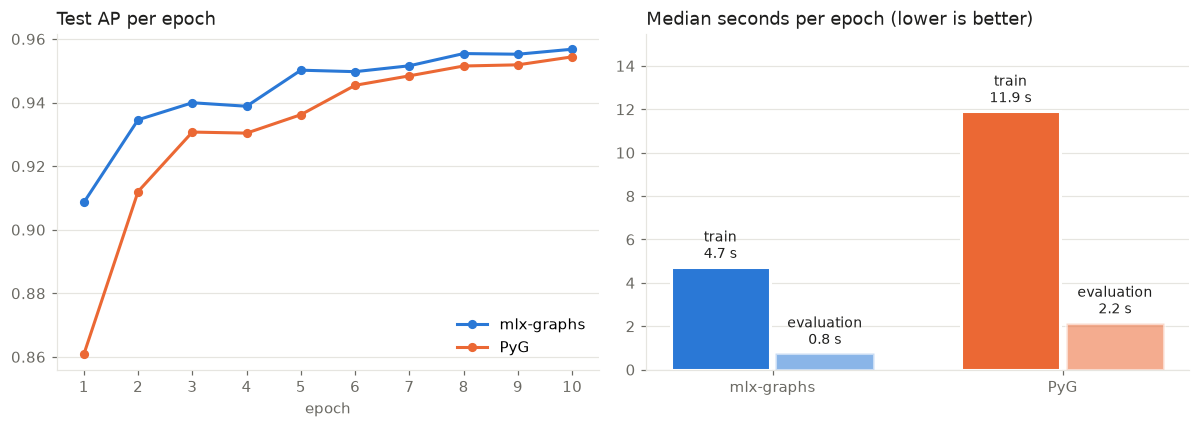

In [12]:
import matplotlib.pyplot as plt

COLORS = {"mlx-graphs": "#2a78d6", "PyG": "#eb6834"}
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e6e5e0"

fig, (ax_ap, ax_time) = plt.subplots(1, 2, figsize=(11, 4))
epochs = np.arange(1, EPOCHS + 1)

for name, history in [("mlx-graphs", mlx_history), ("PyG", pyg_history)]:
    ap = [h["test_ap"] for h in history]
    ax_ap.plot(
        epochs,
        ap,
        color=COLORS[name],
        linewidth=2,
        marker="o",
        markersize=5,
        label=name,
    )

names = ["mlx-graphs", "PyG"]
x = np.arange(2)
width = 0.36
for offset, column, label, alpha in [
    (-width / 2, "train s/epoch", "train", 1.0),
    (width / 2, "eval s/epoch", "evaluation", 0.55),
]:
    values = [summary.loc[n, column] for n in names]
    bars = ax_time.bar(
        x + offset,
        values,
        width - 0.02,
        color=[COLORS[n] for n in names],
        alpha=alpha,
        edgecolor="white",
        linewidth=2,
    )
    for bar, value in zip(bars, values):
        ax_time.annotate(
            f"{label}\n{value:.1f} s",
            (bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            color=INK,
            fontsize=9,
        )

ax_ap.set_title("Test AP per epoch", loc="left", color=INK)
ax_ap.set_xlabel("epoch", color=MUTED)
ax_ap.set_xticks(epochs)
ax_ap.set_xlim(0.5, EPOCHS + 0.5)
ax_ap.legend(frameon=False, loc="lower right")
ax_time.set_title("Median seconds per epoch (lower is better)", loc="left", color=INK)
ax_time.set_xticks(x, names)
ax_time.set_ylim(0, max(summary["train s/epoch"]) * 1.3)
for ax in (ax_ap, ax_time):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
fig.tight_layout()
plt.show()

**Accuracy.** Both models reach a test AP of about 0.95 to 0.96 after 10 epochs, and the gap between them is within the variation between random seeds. The curves differ most in the first epochs, because the two models start from different random weights. The parity tests of mlx-graphs go further: with the same weights, the memory, the losses and the gradients match PyG batch after batch.

**Runtime.** These timings were measured on an Apple M5 Pro, with mlx-graphs on the GPU and PyG on the CPU. mlx-graphs is several times faster than PyG at both training and evaluation (see the speedups printed above). Timings vary from run to run and from machine to machine, so run the notebook on your own machine to compare.

## Going further

- The same code trains on the two other JODIE datasets, `JODIEDataset("mooc")` and `JODIEDataset("lastfm")`.
- `mlx_graphs.metrics` also provides ranking metrics for link prediction (`LinkPredMRR`, `LinkPredNDCG`, `LinkPredHitRatio`, ...), with the same API as `torch_geometric.metrics`.
- [examples/tgn_jodie.py](https://github.com/mlx-graphs/mlx-graphs/blob/main/examples/tgn_jodie.py) is a command-line version of the mlx-graphs part of this tutorial.